# koilog-health — нагрузка, часы Apple Watch и болезни

`koilog.health` связывает внешнюю нагрузку (журнал силовых) с внутренней
(ночной пульс, ВСР, дыхание, температура запястья, сон из Apple Watch) и
находит, как расбаланс предшествует эпизодам болезни. Болезнь здесь — исход,
который связывается с нагрузкой, а не диагноз.

Вся логика живёт в пакете `koilog.health` и вызывается из командной строки;
этот ноутбук — обзор поверх той же базы. Он импортирует **те же** функции, что
и CLI, поэтому расхождений между выводом здесь и в терминале нет.

```
python -m koilog refresh --deep    # всё разом: выгрузка, нагрузка, эпизоды, ML
python -m koilog apple-load        # разобрать выгрузку Apple Health в aw_*
python -m koilog health-load       # внешняя нагрузка: load_daily, health_days
python -m koilog illness           # метки эпизодов: confirmed/probable/gap_only
python -m koilog return            # возврат к весам: кривая, рампа, гейт
python -m koilog digest            # день одной карточкой: каналы и совет
python -m koilog ml                # признаки, CV-отчёт, красный флаг
python -m koilog ml --lag          # + лаг-анализ признаков
```

Пакет держится на стандартной библиотеке. `matplotlib` нужен только этому
ноутбуку (extra `notebook`), `numpy`/`scikit-learn` — только разделу ML
(extra `ml`). Без них остальные разделы работают.

## Как читать числа

Короткий словарь, чтобы колонки и метрики не приходилось угадывать.

**Тоннаж** — суммарный кг за день: Σ (вес × повторы × подходы). **sRPE** —
суррогат тренировочного стресса (тоннаж × целевое RPE); здесь он нормирован
и служит «острой» нагрузкой. **ACWR** — отношение острой (7 дней) к
хронической (28 дней) нагрузке: ~1 — баланс, >1,3 — риск перегруза.

**Монотонность** — среднедневная нагрузка, делённая на её дневной SD за
неделю: чем ровнее и однообразнее неделя, тем выше. **Стрейн** — недельная
нагрузка × монотонность (Foster). **e1RM** — оценка максимума по последнему
подходу; «просадка e1RM» — бинарный флаг регресса.

**Эпизод болезни** — склейка соседних дней с меткой. **`confirmed`** — ручная
температура ≥37,5 °C либо ≥2 нарушенных каналов за день. **`probable`** —
одиночный сильный сигнал автономного ядра (RHR ↑ или ВСР ↓ при z>3). ЧДД и
температура запястья в одиночку эпизод не открывают — они лишь подтверждают.
**`gap_only`** — только перерыв в тренировках ≥14 дней, без физиологии; в
обучение не идёт и отчитывается отдельно.

**z-скор** — отклонение канала от личного фона за предыдущие 60 дней (в SD);
фон — строго прошлые дни, текущий не входит. **Долг сна** — сколько часов за
7 дней недоспал относительно своего обычного сна.

**Красный флаг** (Meeusen) — ≥2 из 4 признаков за 14 дней до эпизода: просадка
e1RM, ВСР ниже обычного, долг сна, монотонность >2. **recall эпизода** — доля
эпизодов, у которых был хотя бы один флагированный день. **ложн./мес** —
сколько дней в месяц модель окажется ложной.

In [1]:
# Шаг обновления: весь конвейер разом (журнал -> выгрузка -> нагрузка ->
# календарь -> эпизоды -> ML). Загрузка журнала и разбор архива скипаются,
# если файл не менялся, а свежесть печатается по таблицам - отставание видно
# сразу. Журнал (sets) грузится первым: его читают нагрузка и эпизоды.
# Печатаем только имя файла и даты: абсолютный путь с именем пользователя
# не должен попадать в сохранённый вывод ноутбука.
import pathlib
import sys

sys.path.insert(0, str(pathlib.Path.cwd()))

from koilog import etl
from koilog.health import (analysis, apple, digest, illness, load, ml,
                           refresh, retrain, text)

conn = etl.connect(etl.DEFAULT_DB)
print(etl.DEFAULT_DB.name)
print(refresh.format_freshness(refresh.run(conn, deep=ml.HAS_ML)))

training.db
обновление: журнал (файл не менялся - скип), выгрузка (файл не менялся - скип), нагрузка, календарь, эпизоды, ML-признаки, скор (записан 2026-10-21)
выгрузка от 2026-10-21 14:22:18 +0300

таблица           дата      
----------------------------
sets              2026-10-21
aw_daily          2026-10-21
load_daily        2026-10-21
health_days       2026-10-21
ml_features       2026-10-21
ml_score          2026-10-21
illness_episodes  2026-10-11


## Покрытие часов по годам

Метрики появляются в выгрузке Apple Watch не все сразу и не с самого начала.
Ниже — сколько дней в каждом году реально содержит каждую метрику. Полезное
окно задано константой `apple.DEFAULT_WINDOW` (2024-01-16): раньше часы пишут
только пульс покоя и сон, без ВСР/ЧДД/температуры, поэтому они в анализ не идут.

In [2]:
# Покрытие метрик по календарным годам. То же: `python -m koilog apple-load`.
print(apple.format_coverage_by_year(apple.coverage_by_year(conn)))
print()
# Сводное покрытие за окно: сколько дней заполнено каждой метрикой.
print(apple.format_coverage(apple.coverage(conn)))

 год  дней  RHR  ВСР  ЧДД  t запястья  SpO2  сон  тренир.
---------------------------------------------------------
2024   351  348  349  348         297   349  350      337
2025   365  365  365  365         314   365  365      381
2026   294  294  294  294         251   294  294      318

дней 1010  (2024-01-16 … 2026-10-21), тренировок 1036, пульса 411957
RHR 1007 (99%), ВСР 1008 (99%), ЧДД 1007 (99%), t запястья 862 (85%), SpO2 1008 (99%), сон 1009 (99%)


## Внешняя нагрузка

`health-load` строит непрерывный календарь нагрузки: дни отдыха — нули, а не
пропуски. Ниже сводка тоннажа, sRPE, ACWR, монотонности и стрейна за окно.

In [3]:
# Сводка нагрузки за окно. То же печатает `python -m koilog health-load`.
print(load.format_summary(conn))

дней в ряду: 1010  (2024-01-16 … 2026-10-21)
подходов: 6236   тоннаж: 1252741 кг
ACWR: средний 1.04, макс 4.00
  пик 4.00 пришёлся на 2026-03-12 - в окне после простоя (gap-aware 0.14); это не перегруз
монотонность: средняя 1.23, макс 2.42, дней > 2: 5
дней с просадкой e1RM: 91


## Симптомная сигнатура

Средние каналов внутренней нагрузки внутри каждого подтверждённого эпизода и в
обычные дни (фон). Это картина гриппоподобной реакции: ночной пульс ↑, ВСР ↓,
ЧДД ↑, температура запястья ↑, сон ↓ (Mishra 2020, Quer 2021, Radin 2020).
Последняя строка — фон, с которым всё сравнивается.

In [4]:
# Сигнатура подтверждённых эпизодов против фона.
rows = analysis.signature(conn)
headers = ["с", "по", "дней", "уровень",
           "RHR", "ВСР", "ЧДД", "t запястья", "сон"]
print(text.table(headers, [
    [r["start"], r["end"], r["days"], r["level"],
     r["RHR, уд/мин"], r["ВСР, мс"], r["ЧДД"],
     r["t запястья, °C"], r["сон, ч"]]
    for r in rows]))

с           по           дней  уровень      RHR    ВСР    ЧДД  t запястья   сон
-------------------------------------------------------------------------------
2024-02-04  2024-02-10      7  confirmed  70.29  38.47  17.74       35.01  6.86
2024-03-10  2024-03-10      1  confirmed   80.0  25.21  17.64        36.0   9.2
2024-05-10  2024-05-10      1  confirmed   72.0   30.0  16.13       35.81  8.48
2024-06-08  2024-06-08      1  confirmed   73.0  36.78  17.38       35.91  5.07
2024-07-17  2024-07-28     12  confirmed  76.08  41.56   16.0       35.32  5.03
2024-10-26  2024-10-26      1  confirmed   73.0  25.84  17.64       35.96  8.43
2024-12-29  2024-12-29      1  confirmed   69.0  26.42  16.65       35.35  6.88
2025-01-03  2025-01-03      1  confirmed   80.0   34.1  17.07       35.85  8.31
2025-03-09  2025-03-13      5  confirmed   66.2  63.62  16.27       35.11  8.21
2025-03-16  2025-03-16      1  confirmed   73.0  27.95  17.06       35.52  7.99
2025-05-18  2025-05-21      4  confirmed

## Эпизоды болезни

Многоуровневые метки. `gap_only` в обучение не идёт и ложится в отчёт
отдельно — «только перерыв» это не болезнь, а отсутствие тренировок.

In [5]:
# Список эпизодов. То же печатает `python -m koilog illness`.
print(illness.format_episodes(conn))

эпизодов: 33  (подтверждённых 19, вероятных 14, только перерыв 0)

с           по          дней  уровень    источник    тип    
------------------------------------------------------------
2024-02-04  2024-02-10     7  confirmed  watch/temp  unknown
2024-02-14  2024-02-15     2  probable   watch/temp  unknown
2024-02-18  2024-02-22     5  probable   watch/temp  unknown
2024-02-29  2024-03-01     2  probable   watch/temp  unknown
2024-03-04  2024-03-05     2  probable   watch/temp  unknown
2024-03-10  2024-03-10     1  confirmed  watch/temp  unknown
2024-04-01  2024-04-02     2  probable   watch/temp  unknown
2024-05-10  2024-05-10     1  confirmed  watch/temp  unknown
2024-05-27  2024-05-28     2  probable   watch/temp  unknown
2024-06-03  2024-06-04     2  probable   watch/temp  unknown
2024-06-08  2024-06-08     1  confirmed  watch/temp  unknown
2024-07-17  2024-07-28    12  confirmed  watch/temp  unknown
2024-10-26  2024-10-26     1  confirmed  watch/temp  unknown
2024-11-27  2024-1

## Спагетти: 28 дней до каждого эпизода

Каждая линия — один эпизод, выровненный по началу болезни (лаг 0 — день до
начала). Тонкие синие — эпизоды, жирная красная — среднее по ним; серые —
контрольные окна тех же размеров из дней, далёких от любой болезни, и их
среднее. Расхождение красной и серой у лага 0 — предболезненный сигнал; без
контрольных окон его нельзя отличить от обычной шумности признака.

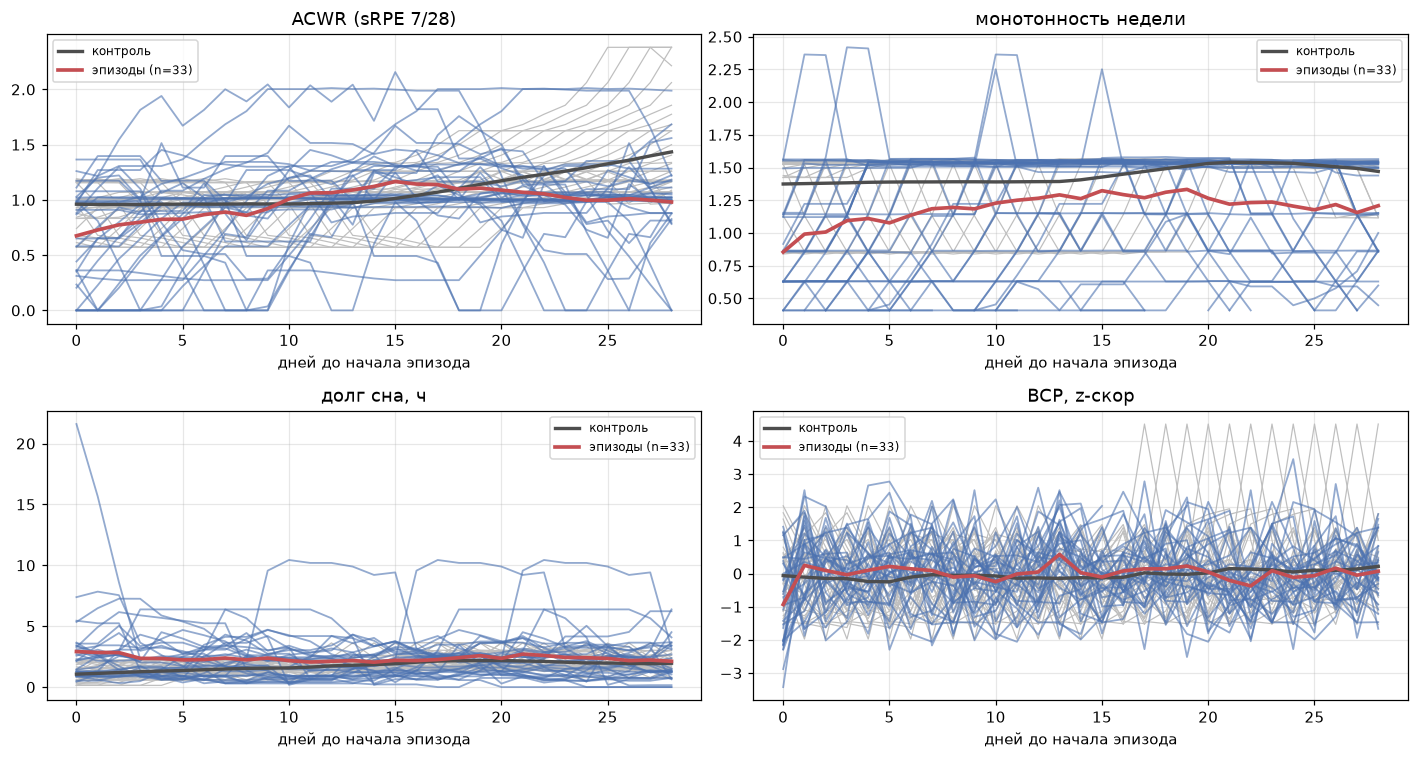

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Четыре признака: ACWR, монотонность, долг сна и ВСР (z-к своему фону).
FEATURES = [
    ("acwr", "ACWR (sRPE 7/28)"),
    ("monotony", "монотонность недели"),
    ("sleep_debt7", "долг сна, ч"),
    ("z_hrv", "ВСР, z-скор"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (feature, title) in zip(axes.ravel(), FEATURES):
    block = analysis.pre_episode_windows(conn, feature)
    lags = block["lags"]
    for row in block["control"]:
        ax.plot(lags, row, color="0.75", lw=0.8)
    for row in block["series"]:
        ax.plot(lags, row, color="#4c72b0", lw=1.2, alpha=0.6)
    ax.plot(lags, block["control_mean"], color="0.3", lw=2.2, label="контроль")
    ax.plot(lags, block["mean"], color="#c44e52", lw=2.4,
            label=f"эпизоды (n={block['n']})")
    ax.set_title(title)
    ax.set_xlabel("дней до начала эпизода")
    ax.legend(loc="best", fontsize=8)
fig.tight_layout()
plt.show()

## Лаг-анализ

Для каждого лага 0–21 день до начала эпизода — насколько среднее признака (в SD
от его личного фона) отклонено относительно всех остальных дней. Это
описательная величина, **без p-value**: при ~30 эпизодах p-value был бы
самообманом.

лаг-анализ: weekly_tonnage

лаг, дн  weekly_tonnage, эффект (SD)   n
----------------------------------------
      0                        -0.61  33
      1                        -0.47  33
      2                        -0.37  33
      3                        -0.26  33
      4                        -0.19  33
      5                        -0.14  33
      6                        -0.08  33
      7                        -0.03  33
      8                        -0.08  33
      9                        -0.00  33
     10                        +0.13  33
     11                        +0.19  33
     12                        +0.21  33
     13                        +0.25  33
     14                        +0.25  33
     15                        +0.30  33
     16                        +0.26  33
     17                        +0.25  33
     18                        +0.23  33
     19                        +0.23  33
     20                        +0.23  32
     21                      

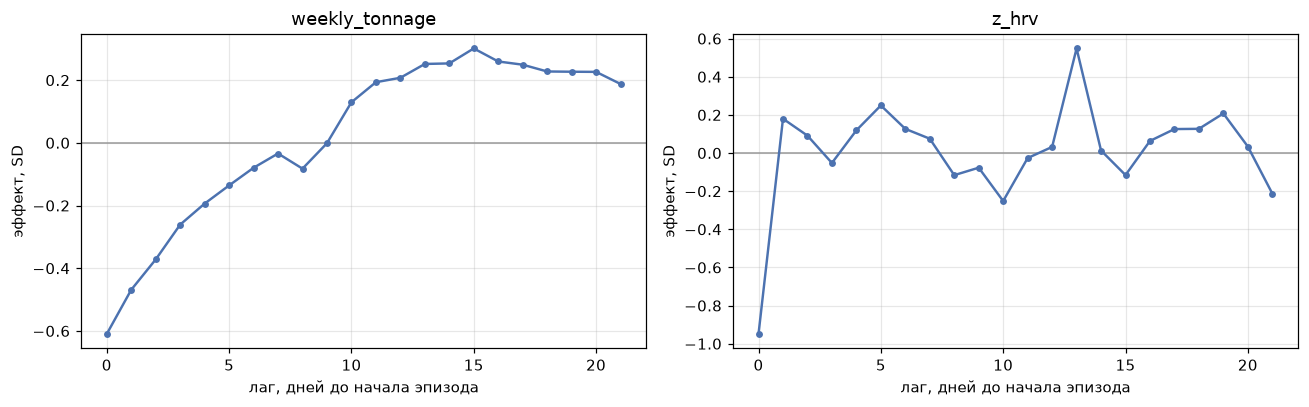

In [7]:
# Лаг-анализ тоннажа и ВСР. То же с ключом --lag: `python -m koilog ml --lag`.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, feature in zip(axes, ("weekly_tonnage", "z_hrv")):
    rows = ml.lag_analysis(conn, feature)
    print(ml.format_lag(rows, feature))
    lags = [r["lag"] for r in rows]
    effect = [r["effect"] if r["effect"] is not None else float("nan")
              for r in rows]
    ax.axhline(0, color="0.6", lw=1)
    ax.plot(lags, effect, marker="o", ms=3.5, lw=1.6, color="#4c72b0")
    ax.set_title(feature)
    ax.set_xlabel("лаг, дней до начала эпизода")
    ax.set_ylabel("эффект, SD")
fig.tight_layout()
plt.show()

## Персональные квантили: предболезненные дни против обычных

Каналы внутренней нагрузки в днях за 14 дней до эпизода (`y=1` в
`ml_features`) против остальных дней. **сдвиг медианы** — насколько медиана
предболезненных дней сдвинута в SD личного фона относительно обычной медианы.

In [8]:
rows = analysis.quantile_profile(conn)
headers = ["канал", "обыч q25", "q50", "q75",
           "предб. q25", "q50", "q75", "сдвиг медианы"]
print(text.table(headers, [
    [r["channel"], r["q25"], r["q50"], r["q75"],
     r["q25_pre"], r["q50_pre"], r["q75_pre"], r["median_shift"]]
    for r in rows]))

канал           обыч q25    q50    q75  предб. q25    q50    q75  сдвиг медианы
-------------------------------------------------------------------------------
RHR, уд/мин         67.0   70.0   73.0        67.0   70.0   73.0            0.0
ВСР, мс            46.15  53.21   60.4       46.11  55.14  63.97           0.17
ЧДД                14.97  15.37  15.77       15.23  15.61  15.99           0.33
t запястья, °C     34.97  35.12   35.3       34.96  35.15   35.3           0.08
сон, ч              6.84   7.22   7.61        6.73   7.16   7.58          -0.06


## ML: CV-отчёт и красный флаг

Протокол — leave-one-episode-out (случайные складки запрещены: временная течь).
**бейзлайн** учитывает только физиологию (без нагрузки), **GBM** — проверка,
стоит ли нелинейная модель своих хлопот.

**Честная оговорка.** Эпизодов ~30 за два года — это не про реальный
предиктор, а про гипотезу. Метрики ниже нужны, чтобы сравнить модели между
собой и найти красный флаг, а не чтобы обещать раннее предупреждение.

In [9]:
# Полный ML-отчёт (пересобирает признаки и метки). То же: `python -m koilog ml`.
data = ml.report(conn)
print(ml.format_report(data))
print()
# Красный флаг Meeusen: ≥2 признака за 14 дней до эпизода.
flag = ml.red_flag_report(conn)
print(f"красный флаг: эпизодов {flag['episodes']}, "
      f"с флагом {flag['episodes_with_flag']}, "
      f"максимум признаков {flag['max_points']}")

окно с 2024-01-16, положительных дней: 337
красный флаг (>=2 признака): эпизодов с флагом 9 из 33

v2: риск эпизода на горизонте 7 дн (поимка при lead >= 3)
модель                эпизодов  поймано  опоздало  медианный lead
-----------------------------------------------------------------
v2 все признаки             33       17        10               6
v2 только физиология        33       18         7               5
ложные срабатывания считаются только бюджетно (см. recall@бюджет): порог 0.5 здесь не operating point и цифру сравнивать не с чем

recall@бюджет (все признаки, причинные метки causal-v2, день за днём, порог по прошлому, поимка при lead >= 3)
эпизодов 32, уловимых 22; 7 неуловимы вовсе (lead>=3-окно целиком в болезни соседнего эпизода); 3 без истории (первые дни ряда)
цель/мес  факт/мес  recall  precision  поймано  случайный
---------------------------------------------------------
       2       0.5    0.00       0.06        0       0.10
       4       1.5    0.05       0.

## Возврат к весам после болезни

Когда болезнь прерывает цикл, сила у тренированных почти не падает 2–3 недели
(Mujika & Padilla 2000), но возвращаться надо от последнего «до болезни» рабочего
веса упражнения, а не от общего плана. Сверху — рампа возврата и гейт ВСР/RHR:
от какого веса и объёма стартовать; ниже — разметка прошлых возвратов и личная
детрейн-кривая, а литературные ориентиры — в самом конце. Шаги рампы подбираются так, чтобы полный
предболезненный вес возвращался **внутри** полосы, а не когда-то потом. Это
описание личных данных, а не доказательство: эпизодов единицы.


In [10]:
# Возврат по самому частому упражнению. То же: `python -m koilog return`.
# Берём упражнение с внешним весом: у подтягиваний рампа не строится
# (вес свой, а не снаряд), это не самый показательный пример.
exercise = "Приседания с гантелями"
# Сначала расчёты: рампа возврата и прошлые возвраты.
print(retrain.format_return(retrain.return_plan(conn, exercise)))
print()
print(retrain.format_returns(retrain.returns(conn, exercise), exercise))
print()
# Потом описательная кривая; литературные ориентиры - в её конце.
print(retrain.format_curve(retrain.detraining_curve(conn, exercise), exercise))


=== возврат к весам: Приседания с гантелями ===
предболезненный вес: 64 кг x 8 (2026-10-05), 1RM 79.4, КОИ упражнения 1.42, КОИ за неделю 2026-W41: 1.42
простой: 16 дн  →  полоса «2–4 недели», верх 1-й недели 85% от базы, объём −25%, полный возврат ~3 нед (один шаг в неделю)
первая неделя: 44/50/54; верх 54 кг (цель 54.4 кг), подходов 3; повторы подобраны так, чтобы КОИ тренировки оставался в Optimal
полный вес достигается на шаге 3 (неделя 3) - дальше растим повторы и добавляем мощность последней

рампа (подходы - лесенка с перекрытием недель, доля и нагрузка - по верхнему):
шаг  подходы         доля  нагрузка   КОИ  режим  
--------------------------------------------------
  1  44x8 50x8 54x8   84%       68%  0.64  Optimal
  2  50x8 54x8 58x8   91%       73%  0.76  Optimal
  3  54x8 58x8 64x8  100%       81%  0.96  Optimal

гейт ВСР/RHR: держать, рано  (ночей проверено: 2, сегодня 2026-10-21)
ночь        RHR  z RHR  ВСР  z ВСР  t зап.   z t
------------------------------------------

## Дневной дайджест

Одна карточка дня сводит часы, нагрузку и **одну** рекомендацию. Каналы часов
показаны как z к личному фону за 60 дней (красные — отклонились в «плохую»
сторону). Приоритет рекомендации: красный флаг недовосстановления (Meeusen 2013)
→ покой (активный эпизод или гейт не пройден) → «завтра легко» (ЧДД, RHR и ВСР
отклонились вместе) → рампа (возврат после простоя) → «можно по плану». То же
печатает `python -m koilog digest`.


дневной дайджест: 2026-10-21

канал       значение     z  статус
----------------------------------
RHR            71.00  +1.2  в фоне
ВСР            58.27  +0.2  в фоне
ЧДД            14.80  -1.2  в фоне
t запястья                  —     
SpO2           96.22  +0.2  в фоне
сон             7.17  +0.3  в фоне

нагрузка за 2026-10-21: ACWR 0.9 (gap-aware 0.9), монотонность 0.9, стрейн 5950.7
  тоннаж недели 6990.0 кг, дней с последней тренировки 0

гейт возврата: держит — 2026-10-21: RHR z +1.2 выше фона (>1); 2026-10-20: RHR z +1.5 выше фона (>1); окно тишины после эпизода 2026-10-11…2026-10-13: возврат по рампе до 2026-10-27
  полоса гейта: порог ±1 (каналы ±1.5); ночей 2 — держит
состояние: покой (гейт держит) (рампа приостановлена)
по группам: жим лёжа/iron 1320 кг (n=1); жим вертикальный/iron — (n=0); приседания/iron 1404 кг (n=1); приседания/bodyweight — (n=0); жим ногами/iron — (n=0); становая тяга/iron 1404 кг (n=1); тяга вертикальная/iron — (n=0); тяга вертикальная/bodyweight — 

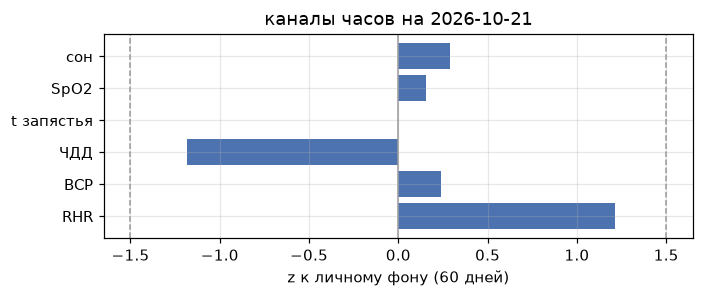

In [11]:
# Карточка последнего дня с данными. То же: `python -m koilog digest`.
state = digest.day_state(conn)
print(digest.format_digest(state))

fig, ax = plt.subplots(figsize=(6.5, 2.8))
labels = [c.label for c in state["channels"]]
values = [c.z if c.z is not None else 0.0 for c in state["channels"]]
colors = ["#c44e52" if c.bad else "#4c72b0" for c in state["channels"]]
ax.barh(labels, values, color=colors)
ax.axvline(0, color="0.6", lw=1)
for bound in (digest.Z_CHANNEL, -digest.Z_CHANNEL):
    ax.axvline(bound, color="0.6", lw=1, ls="--")
ax.set_xlabel("z к личному фону (60 дней)")
ax.set_title(f"каналы часов на {state['today']}")
fig.tight_layout()
plt.show()
